# 원하는 포즈로 이미지 만드는 도구 (FLUX.2-klein-4B + OpenPose)

참조 사진 한 장의 **자세(포즈)** 를 그대로 따라 하는 **다른 인물·장면** 이미지를 만드는 튜토리얼입니다.
교안의 *FLUX.2-klein-4B (Colab + ComfyUI)* 노트를 출발점으로, 여기에 **OpenPose 포즈 조건**을 얹었습니다.

---

## 전체 흐름

```
참조 사진 ──▶ OpenPose ──▶ 스켈레톤(막대 인형) 그림 ──┐
                                                         ├──▶ FLUX.2-klein-4B ──▶ 같은 자세의 새 이미지
프롬프트 ("a knight in armor ...") ─────────────────────┘
```

| 단계 | 하는 일 | 셀 |
|---|---|---|
| 준비 | GPU 확인, ComfyUI·OpenPose 설치, 모델 다운로드, 서버 실행 | 1 ~ 4 |
| 도구 | 포즈 조건 생성 함수 정의 | 5 |
| 실행 | 참조 사진 업로드 → 포즈 추출 → 이미지 생성 → 결과 저장 | 6 ~ 9 |
| 실험 | 같은 포즈·다른 프롬프트 / 다른 포즈·같은 프롬프트 | 10 ~ 11 |
| 마무리 | 결과 다운로드, 관찰 기록 | 12 ~ 13 |

---

## 핵심 개념

**OpenPose** 는 사진 속 사람의 관절(코·어깨·팔꿈치·손목·골반·무릎·발목 등)을 찾아
색깔 있는 **선과 점으로 이은 스켈레톤 그림**으로 바꿔 줍니다. 옷·얼굴·배경 정보는 버리고 *자세만* 남는 것이 포인트입니다.

**포즈를 모델에 넣는 방법**
- SD 1.5 / SDXL 같은 예전 모델은 **ControlNet** 이라는 별도 모델을 붙여 스켈레톤을 조건으로 넣었습니다.
- FLUX.2 계열은 **참조 이미지(Reference Latent)** 를 직접 입력받을 수 있어서, 별도 ControlNet 모델 없이
  스켈레톤 그림을 참조 이미지로 넣고 프롬프트로 *"이 스켈레톤의 자세를 따르라"* 고 지시합니다.
  (ComfyUI 의 `ReferenceLatent` 노드 사용)

---

## 실습 준비
1. 상단 메뉴 **[런타임 → 런타임 유형 변경 → T4 GPU]** 선택 후 저장
2. **참조용 사람 사진 3장**을 미리 PC에 준비 (전신이 보이고, 배경이 단순하고, 팔다리가 잘 보이는 사진)
   - 추천: ① 한 손을 든 서 있는 자세 ② 의자에 앉은 자세 ③ 점프·달리기 같은 역동적인 자세
   - 무료 사진: Unsplash, Pexels 에서 `standing pose`, `sitting on chair`, `jumping` 등으로 검색
3. 아래 셀을 **1번부터 순서대로** 실행

## [단계 1] 런타임에 GPU 가 있는지 확인

이 실습은 GPU 없이는 실행할 수 없습니다. 현재 Colab 런타임이 GPU 를 인식하는지, 어떤 종류(T4 등)이고 VRAM 이 얼마인지 확인합니다.

GPU 가 감지되지 않으면 **[런타임 → 런타임 유형 변경 → T4 GPU]** 로 바꾼 뒤 이 셀을 다시 실행하세요.

In [1]:
# 1) GPU 가 사용 가능한지 확인
import torch

print("PyTorch 버전:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU가 없습니다. [런타임 → 런타임 유형 변경 → T4 GPU] 후 다시 실행하세요.")

PyTorch 버전: 2.14.1+cu130
CUDA 사용 가능: True
GPU: Tesla T4
VRAM(GB): 15.64


## [단계 2] ComfyUI · GGUF 노드 · OpenPose 설치

- **ComfyUI**: 노드 기반 이미지 생성 도구. 여기서는 화면 없이 **API 서버**로만 사용합니다.
- **ComfyUI-GGUF**: 양자화(GGUF) 모델을 읽기 위한 플러그인.
- **controlnet_aux** *(새로 추가)*: OpenPose 등 "조건 이미지"를 만드는 전처리 도구 모음. 여기서 OpenPose 를 꺼내 씁니다.

In [2]:
# 2) ComfyUI 본체 + GGUF 노드(플러그인) 설치
import os

%cd /content
if not os.path.isdir("/content/ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git   # ComfyUI 본체

%cd /content/ComfyUI
!pip install -q -r requirements.txt                            # ComfyUI 의존성

# GGUF 파일을 읽기 위한 커스텀 노드 설치
%cd /content/ComfyUI/custom_nodes
if not os.path.isdir("ComfyUI-GGUF"):
    !git clone https://github.com/city96/ComfyUI-GGUF.git      # GGUF 로더 노드
%cd /content/ComfyUI
!pip install -q gguf                                           # GGUF 파싱 라이브러리

print("\n완료: ComfyUI + GGUF 노드 설치")

# ── [추가] 포즈 추출 라이브러리 설치 ──
#    controlnet_aux 안에 OpenPose 전처리기가 들어 있습니다.
!pip install -q controlnet_aux
print("완료: controlnet_aux(OpenPose) 설치")

/content
Cloning into 'ComfyUI'...
remote: Enumerating objects: 65068, done.
remote: Counting objects: 100% (864/864), done.
remote: Compressing objects: 100% (251/251), done.
remote: Total 65068 (delta 741), reused 613 (delta 613), pack-reused 64204 (from 2)
Receiving objects: 100% (65068/65068), 99.81 MiB | 18.10 MiB/s, done.
Resolving deltas: 100% (45054/45054), done.
/content/ComfyUI
/content/ComfyUI/custom_nodes
Cloning into 'ComfyUI-GGUF'...
remote: Enumerating objects: 814, done.
remote: Counting objects: 100% (570/570), done.
remote: Compressing objects: 100% (207/207), done.
remote: Total 814 (delta 515), reused 363 (delta 363), pack-reused 244 (from 1)
Receiving objects: 100% (814/814), 187.88 KiB | 8.54 MiB/s, done.
Resolving deltas: 100% (545/545), done.
/content/ComfyUI

완료: ComfyUI + GGUF 노드 설치
완료: controlnet_aux(OpenPose) 설치


## [단계 3] 모델 파일 3종 다운로드

FLUX.2-klein 파이프라인을 이루는 세 파일을 ComfyUI 표준 폴더에 받습니다. (총 약 11GB, 시간이 꽤 걸립니다)

| 역할 | 파일 | 설명 |
|---|---|---|
| 디퓨전 모델 | `flux-2-klein-4b-Q4_K_M.gguf` (2.6GB) | 이미지를 그려내는 핵심. 4비트 양자화본 |
| 텍스트 인코더 | `qwen_3_4b.safetensors` (8GB) | 프롬프트를 숫자로 변환 |
| VAE | `flux2-vae.safetensors` (330MB) | 이미지 ↔ latent 변환. **이번엔 스켈레톤 그림을 latent 로 바꾸는 데도 사용** |

이미 받은 파일은 건너뛰므로, 런타임이 끊긴 뒤 다시 실행해도 처음부터 받지 않습니다.

> OpenPose 가중치(약 200MB)는 단계 7에서 처음 실행할 때 자동으로 받습니다.

In [3]:
# 3) 파이프라인 구성 파일 3종 다운로드 → ComfyUI 표준 폴더에 배치
import os
%cd /content/ComfyUI

# ComfyUI 가 모델을 찾는 표준 경로 생성
os.makedirs("models/diffusion_models", exist_ok=True)   # 디퓨전 모델
os.makedirs("models/text_encoders",  exist_ok=True)   # 텍스트 인코더
os.makedirs("models/vae",            exist_ok=True)   # VAE

def 다운로드(url, 저장경로):
    """이미 받았으면 건너뛰고, 아니면 wget 로 받는 헬퍼"""
    if os.path.exists(저장경로) and os.path.getsize(저장경로) > 1_000_000:
        print(f"  ↳ 이미 있음: {저장경로} ({os.path.getsize(저장경로)/1e9:.2f} GB)")
        return
    print(f"  ↳ 다운로드 중...")
    !wget -q --show-progress -O "{저장경로}" "{url}"

print("[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)")
다운로드("https://huggingface.co/unsloth/FLUX.2-klein-4B-GGUF/resolve/main/flux-2-klein-4b-Q4_K_M.gguf",
        "models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf")

print("[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/text_encoders/qwen_3_4b.safetensors",
        "models/text_encoders/qwen_3_4b.safetensors")

print("[3/3] VAE (약 330MB)")
다운로드("https://huggingface.co/Comfy-Org/vae-text-encorder-for-flux-klein-4b/resolve/main/split_files/vae/flux2-vae.safetensors",
        "models/vae/flux2-vae.safetensors")

print("\n다운로드 완료. 배치된 파일 확인:")
!ls -lh models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf \
      models/text_encoders/qwen_3_4b.safetensors \
      models/vae/flux2-vae.safetensors

/content/ComfyUI
[1/3] 디퓨전 모델 (GGUF Q4, 약 2.6GB)
  ↳ 다운로드 중...
models/diffusion_mo 100%[===================>]   2.42G  40.8MB/s    in 27s     
[2/3] 텍스트 인코더 (Qwen3-4B, 약 8GB)
  ↳ 다운로드 중...
models/text_encoder 100%[===================>]   7.49G   244MB/s    in 45s     
[3/3] VAE (약 330MB)
  ↳ 다운로드 중...
models/vae/flux2-va 100%[===================>] 320.64M   168MB/s    in 1.9s    

다운로드 완료. 배치된 파일 확인:
-rw-r--r-- 1 root root 2.5G Nov 11 07:18 models/diffusion_models/flux-2-klein-4b-Q4_K_M.gguf
-rw-r--r-- 1 root root 7.5G Nov 11 07:19 models/text_encoders/qwen_3_4b.safetensors
-rw-r--r-- 1 root root 321M Nov 11 07:19 models/vae/flux2-vae.safetensors


## [단계 4] ComfyUI 서버 실행

ComfyUI 를 **백그라운드**로 띄웁니다. 서버는 Colab 내부의 `http://127.0.0.1:8188` 에서 동작하고,
다음 단계에서 만들 생성 함수가 이 서버에 작업을 보냅니다. `완료` 메시지가 나오면 준비된 것입니다.

In [4]:
# 4) ComfyUI 서버를 백그라운드로 실행 (Gradio 가 이 서버에 접속함)
#    ※ Gradio 를 쓰므로 외부 공개 터널은 필요 없습니다.
import subprocess, os, time

%cd /content/ComfyUI

# 혹시 떠 있는 예전 서버가 있으면 정리
!pkill -f "main.py" 2>/dev/null
time.sleep(2)

# ComfyUI 백그라운드 실행 (포트 8188)
os.system("nohup python main.py --listen 0.0.0.0 --port 8188 > /content/comfyui.log 2>&1 &")

# 서버가 뜰 때까지 대기 (로컬에서 200 응답이 오면 준비 완료)
print("ComfyUI 기동 대기 중...")
for _ in range(40):
    time.sleep(1)
    code = subprocess.run("curl -s -o /dev/null -w '%{http_code}' http://127.0.0.1:8188/",
                          shell=True, capture_output=True, text=True).stdout
    if code == "200":
        print("완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)")
        break
else:
    print("서버가 안 뜹니다. 로그:")
    print(open("/content/comfyui.log").read()[-800:])

/content/ComfyUI
^C
ComfyUI 기동 대기 중...
완료: ComfyUI 서버 준비 (http://127.0.0.1:8188)


## [단계 5] 포즈 조건 이미지 생성 함수 만들기 (도구의 핵심)

교안의 Gradio 셀에 있던 `generate()` 함수를 바탕으로, **스켈레톤 그림을 참조 이미지로 넣는 노드 3개**를 추가했습니다.

| 노드 | 역할 | 교안 대비 |
|---|---|---|
| `LoadImage` | 스켈레톤 PNG 를 불러옴 | **추가** |
| `VAEEncode` | 스켈레톤 그림을 모델이 읽는 latent 로 압축 | **추가** |
| `ReferenceLatent` | 프롬프트 조건에 "이 그림을 참고하라"는 정보를 붙임 | **추가** |
| 나머지 (모델 로드 → 인코딩 → KSampler → VAEDecode → 저장) | 그대로 | 동일 |

또한 프롬프트 앞뒤에 **포즈 지시문**을 자동으로 붙입니다.
사용자는 *"누구를, 어디에"* 만 적으면 되고, *"스켈레톤의 자세를 따르고 선은 그리지 마라"* 는 지시는 함수가 대신 넣어 줍니다.

`skeleton_path=None` 으로 부르면 포즈 조건 **없이** 생성합니다 (실험에서 비교용으로 사용).

이 셀은 함수를 **정의만** 하므로 실행해도 아무 이미지도 나오지 않는 것이 정상입니다.

In [5]:
# 5) 포즈 조건 생성 함수 + 결과 비교용 보조 함수 정의
import requests, time, json, urllib.parse, shutil, os, io
from PIL import Image
import matplotlib.pyplot as plt

SERVER    = "http://127.0.0.1:8188"          # 단계 4에서 띄운 ComfyUI 서버
COMFY_IN  = "/content/ComfyUI/input"         # ComfyUI 가 LoadImage 로 읽는 폴더
SAMPLES   = "/content/pose-image-tool/samples"   # 결과를 모아 둘 폴더 (GitHub 업로드용)
os.makedirs(COMFY_IN, exist_ok=True)
os.makedirs(SAMPLES, exist_ok=True)

# ── 생성 설정 (실험 중에는 바꾸지 말고 고정해야 비교가 공정합니다) ──
STEPS = 4      # distilled 모델은 4 스텝 권장 (교안과 동일)
CFG   = 4.0    # 교안과 동일. 포즈가 잘 안 따라오면 1.0~2.0 도 시도해 볼 것
SEED  = 42     # 시드를 고정하면 "바꾼 조건" 의 효과만 비교할 수 있음

# ── 프롬프트 앞뒤에 자동으로 붙는 포즈 지시문 ──
POSE_PREFIX = ("The reference image is an OpenPose skeleton (a colored stick figure on a black background). "
               "Generate a photo of ")
POSE_SUFFIX = (", in exactly the same full-body pose as the skeleton: match the head direction, "
               "both arms and both legs. Do not draw any skeleton lines, colored dots or stick figure; "
               "render a natural, realistic scene.")

def build_prompt(subject, use_pose=True):
    """사용자가 적은 subject(누가, 어디서)에 포즈 지시문을 붙여 최종 프롬프트를 만든다."""
    return POSE_PREFIX + subject + POSE_SUFFIX if use_pose else subject


def generate_with_pose(skeleton_path, subject, seed=SEED, steps=STEPS, cfg=CFG, size=None):
    """스켈레톤 그림 + 프롬프트 → ComfyUI 워크플로우 조립 → 생성 → PIL 이미지 반환

    skeleton_path : 단계 7에서 만든 스켈레톤 PNG 경로 (None 이면 포즈 조건 없이 생성)
    subject       : 만들고 싶은 인물/장면 설명 (영어 권장)
    size          : (가로, 세로). None 이면 스켈레톤 그림 크기를 그대로 사용
    """
    use_pose = skeleton_path is not None
    if use_pose:
        # ① 스켈레톤 그림을 ComfyUI 입력 폴더로 복사 (LoadImage 노드가 이 폴더에서 읽음)
        name = os.path.basename(skeleton_path)
        shutil.copy(skeleton_path, os.path.join(COMFY_IN, name))
        w, h = Image.open(skeleton_path).size
    else:
        w, h = size or (1024, 1024)
    if size:
        w, h = size

    prompt = build_prompt(subject, use_pose)

    # ② 워크플로우(노드 그래프) — 교안과 같은 번호를 쓰고, 12~16번 노드를 새로 추가
    wf = {
      "10": {"class_type": "UnetLoaderGGUF", "inputs": {"unet_name": "flux-2-klein-4b-Q4_K_M.gguf"}},
      "8":  {"class_type": "CLIPLoader",     "inputs": {"clip_name": "qwen_3_4b.safetensors", "type": "flux2"}},
      "6":  {"class_type": "CLIPTextEncode", "inputs": {"text": prompt, "clip": ["8", 0]}},
      "7":  {"class_type": "CLIPTextEncode", "inputs": {"text": "", "clip": ["8", 0]}},
      "4":  {"class_type": "VAELoader",      "inputs": {"vae_name": "flux2-vae.safetensors"}},
      "5":  {"class_type": "EmptyLatentImage", "inputs": {"width": int(w), "height": int(h), "batch_size": 1}},
    }
    pos, neg = ["6", 0], ["7", 0]
    if use_pose:
        wf.update({
          "12": {"class_type": "LoadImage",       "inputs": {"image": name}},                              # 스켈레톤 불러오기
          "14": {"class_type": "VAEEncode",       "inputs": {"pixels": ["12", 0], "vae": ["4", 0]}},       # 그림 → latent
          "15": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["6", 0], "latent": ["14", 0]}},  # 긍정 조건에 참조 붙이기
          "16": {"class_type": "ReferenceLatent", "inputs": {"conditioning": ["7", 0], "latent": ["14", 0]}},  # 부정 조건에도 동일하게
        })
        pos, neg = ["15", 0], ["16", 0]
    wf.update({
      "3":  {"class_type": "KSampler", "inputs": {"seed": int(seed), "steps": int(steps), "cfg": float(cfg),
                                                  "sampler_name": "euler", "scheduler": "simple", "denoise": 1.0,
                                                  "model": ["10", 0], "positive": pos, "negative": neg,
                                                  "latent_image": ["5", 0]}},
      "9":  {"class_type": "VAEDecode", "inputs": {"samples": ["3", 0], "vae": ["4", 0]}},
      "11": {"class_type": "SaveImage", "inputs": {"images": ["9", 0], "filename_prefix": "pose_tool"}},
    })

    # ③ 서버에 작업 전송
    r = requests.post(f"{SERVER}/prompt", json={"prompt": wf, "client_id": "colab"}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"요청 실패 {r.status_code}: {r.text[:500]}")
    pid = r.json()["prompt_id"]

    # ④ 끝날 때까지 2초마다 확인 (최대 10분)
    t0 = time.time()
    for _ in range(300):
        time.sleep(2)
        try:
            hist = requests.get(f"{SERVER}/history/{pid}", timeout=10).json()
        except Exception:
            continue
        if pid in hist:
            entry = hist[pid]
            if entry.get("status", {}).get("status_str") == "error":
                raise RuntimeError("ComfyUI 실행 에러: " + json.dumps(entry["status"].get("messages", []), ensure_ascii=False)[:800])
            img_info = entry["outputs"]["11"]["images"][0]
            break
    else:
        raise TimeoutError("10분 안에 끝나지 않았습니다. /content/comfyui.log 를 확인하세요.")

    # ⑤ 결과 이미지 받아서 PIL 로 반환
    q = urllib.parse.urlencode({"filename": img_info["filename"], "subfolder": img_info.get("subfolder", ""),
                                "type": img_info.get("type", "output")})
    img = Image.open(io.BytesIO(requests.get(f"{SERVER}/view?{q}", timeout=30).content)).convert("RGB")
    print(f"  생성 완료 ({time.time()-t0:.1f}초, {w}x{h}, pose={'ON' if use_pose else 'OFF'}) : {subject[:60]}")
    return img


def show_row(images, titles, save_path=None, height=4):
    """이미지 여러 장을 가로로 나란히 보여 주고, save_path 가 있으면 비교 그림으로 저장"""
    fig, axes = plt.subplots(1, len(images), figsize=(height * len(images), height))
    if len(images) == 1:
        axes = [axes]
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=100, bbox_inches="tight")
    plt.show()

print("완료: generate_with_pose(), show_row() 함수 정의")

완료: generate_with_pose(), show_row() 함수 정의


## [단계 6] 참조 사진 업로드

실행하면 **[파일 선택]** 버튼이 나타납니다. 준비한 사람 사진 **3장**을 한 번에 골라 올리세요.

- 올린 순서(파일 이름 순)대로 `samples/pose_01.png`, `pose_02.png`, `pose_03.png` 로 저장됩니다.
- 이 파일들이 과제의 **"참조로 쓴 포즈 이미지"** 입니다.
- 사진 고르는 팁: 전신이 다 보이고, 사람이 한 명이고, 팔다리가 몸에 가려지지 않은 사진일수록 포즈가 정확하게 잡힙니다.

Saving 3.png to 3.png
Saving 2.png to 2.png
Saving 1.png to 1.png
1.png  →  /content/pose-image-tool/samples/pose_01.png  (2752x1536)
2.png  →  /content/pose-image-tool/samples/pose_02.png  (2752x1536)
3.png  →  /content/pose-image-tool/samples/pose_03.png  (2752x1536)


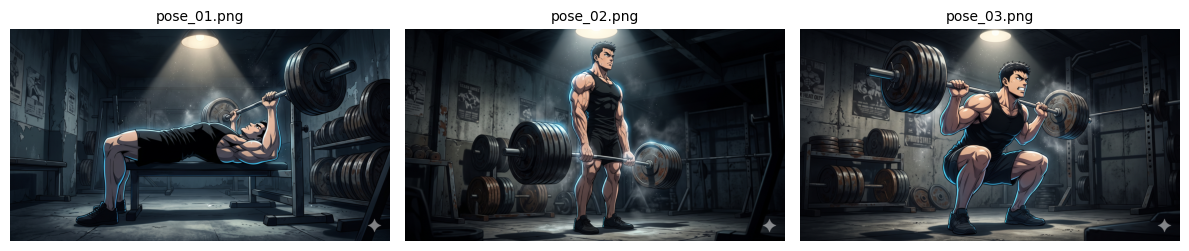

In [6]:
# 6) 참조 사진 업로드 → samples/pose_0N.png 로 저장
from google.colab import files

uploaded = files.upload()          # 파일 선택 창이 뜸 (여러 장 동시 선택 가능)

pose_photos = []                   # 이후 셀에서 쓸 참조 사진 경로 목록
for i, fname in enumerate(sorted(uploaded.keys()), start=1):
    img = Image.open(io.BytesIO(uploaded[fname])).convert("RGB")
    path = f"{SAMPLES}/pose_{i:02d}.png"
    img.save(path)
    pose_photos.append(path)
    print(f"{fname}  →  {path}  ({img.size[0]}x{img.size[1]})")

show_row([Image.open(p) for p in pose_photos], [os.path.basename(p) for p in pose_photos])

## [단계 7] 포즈 추출 (OpenPose)

각 참조 사진에서 OpenPose 로 관절을 찾아 **스켈레톤 그림**을 만듭니다.

- 몸통·팔·다리뿐 아니라 **손가락(hand)과 얼굴(face) 점**까지 함께 뽑습니다.
- 스켈레톤 크기는 긴 변 1024px 기준으로 맞추고, 가로·세로를 64의 배수로 다듬습니다 (생성 모델이 좋아하는 크기).
- 결과는 `samples/pose_0N_skeleton.png` 로 저장되고, 이 그림이 단계 8에서 **포즈 조건**으로 들어갑니다.

> **확인 포인트**: 스켈레톤이 사람 자세와 맞게 그려졌나요? 여기서 관절이 틀리면 생성 결과도 틀립니다.
> 관절이 비어 있거나 엉뚱하면 다른 사진으로 바꾸는 것이 가장 빠른 해결책입니다.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarni

body_pose_model.pth: reconstructing file:   0%|          |  0.00B /  209MB            

body_pose_model.pth: downloading bytes:           |  0.00B            

hand_pose_model.pth: reconstructing file:   0%|          |  0.00B /  147MB            

hand_pose_model.pth: downloading bytes:           |  0.00B            

facenet.pth: reconstructing file:   0%|          |  0.00B /  154MB            

facenet.pth: downloading bytes:           |  0.00B            

pose_01.png → pose_01_skeleton.png (1024x576)
pose_02.png → pose_02_skeleton.png (1024x576)
pose_03.png → pose_03_skeleton.png (1024x576)


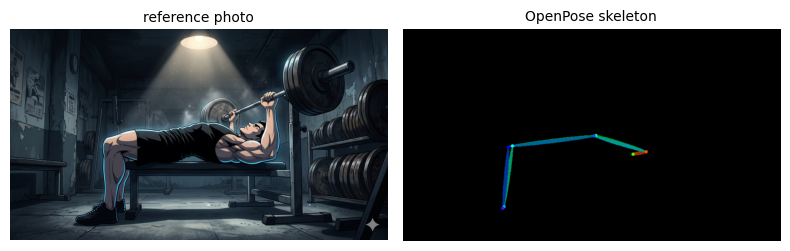

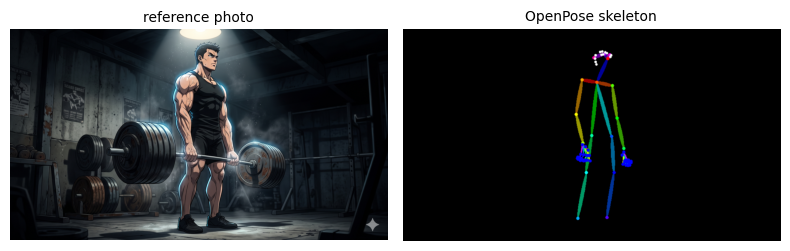

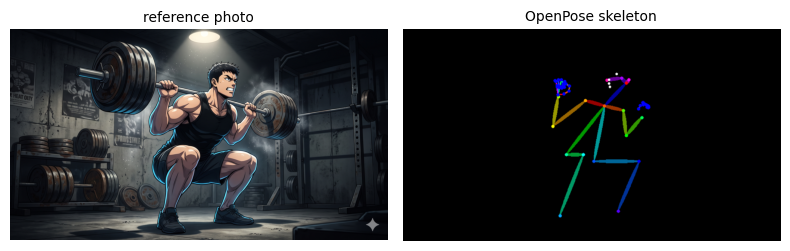

In [7]:
# 7) 참조 사진 → OpenPose 스켈레톤 그림
import sys
sys.modules["mediapipe"] = None     # Colab 의 최신 mediapipe 와 controlnet_aux 충돌 방지 (OpenPose 에는 필요 없음)
from controlnet_aux import OpenposeDetector

openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")   # 첫 실행 시 가중치 자동 다운로드

def target_size(w, h, long_side=1024):
    """긴 변을 long_side 로 맞추고 64의 배수로 반올림"""
    s = long_side / max(w, h)
    return max(64, round(w * s / 64) * 64), max(64, round(h * s / 64) * 64)

skeletons = []                      # 스켈레톤 그림 경로 목록 (pose_photos 와 같은 순서)
for p in pose_photos:
    photo = Image.open(p).convert("RGB")
    W, H = target_size(*photo.size)
    sk = openpose(photo, detect_resolution=512, image_resolution=1024,
                  include_body=True, include_hand=True, include_face=True)
    sk = sk.resize((W, H), Image.NEAREST)
    sk_path = p.replace(".png", "_skeleton.png")
    sk.save(sk_path)
    skeletons.append(sk_path)
    print(f"{os.path.basename(p)} → {os.path.basename(sk_path)} ({W}x{H})")

# 참조 사진과 스켈레톤을 나란히 비교
for p, s in zip(pose_photos, skeletons):
    show_row([Image.open(p), Image.open(s)], ["reference photo", "OpenPose skeleton"])

## [단계 8] 포즈 조건으로 이미지 생성

각 포즈마다 프롬프트를 하나씩 정해 **같은 자세의 다른 인물/장면**을 만듭니다.

- `subjects` 리스트의 순서가 `pose_01`, `pose_02`, `pose_03` 에 대응합니다.
- **"누가, 어디서, 어떤 스타일로"** 만 영어로 적으면 됩니다. 포즈 지시문은 함수가 자동으로 붙입니다.
- 자세를 묘사하는 단어(`sitting`, `jumping` 등)는 일부러 넣지 않았습니다. 그래야 **포즈가 프롬프트가 아니라 스켈레톤에서 왔다**는 것을 확인할 수 있습니다.
- T4 기준 한 장에 수십 초~1분 정도 걸립니다. 첫 장은 모델 로드 때문에 더 오래 걸립니다.

> 사진 내용에 맞게 `subjects` 를 자유롭게 바꿔도 됩니다. 바꾼 프롬프트는 `prompts.md` 에도 기록하세요.

  생성 완료 (26.2초, 1024x576, pose=ON) : a female astronaut in a white spacesuit on the surface of th
  생성 완료 (30.1초, 1024x576, pose=ON) : a cute small robot made of shiny metal, 3D cartoon render, p
  생성 완료 (30.1초, 1024x576, pose=ON) : an old fisherman in a yellow raincoat on a wooden boat, oil 


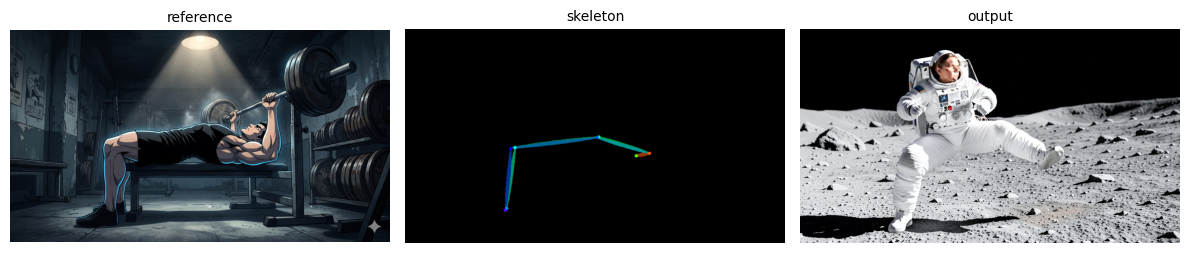

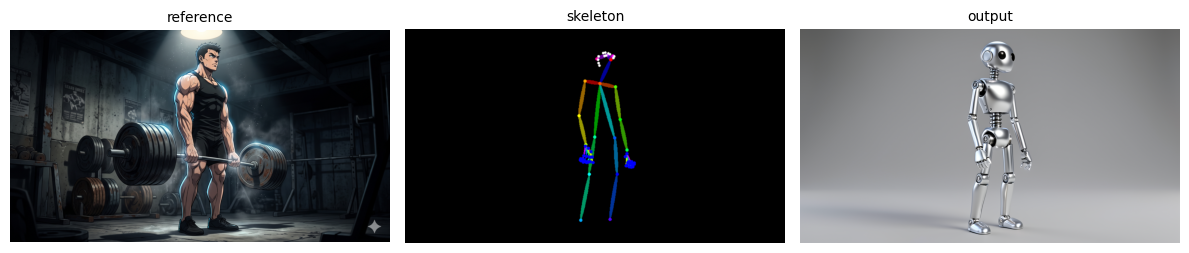

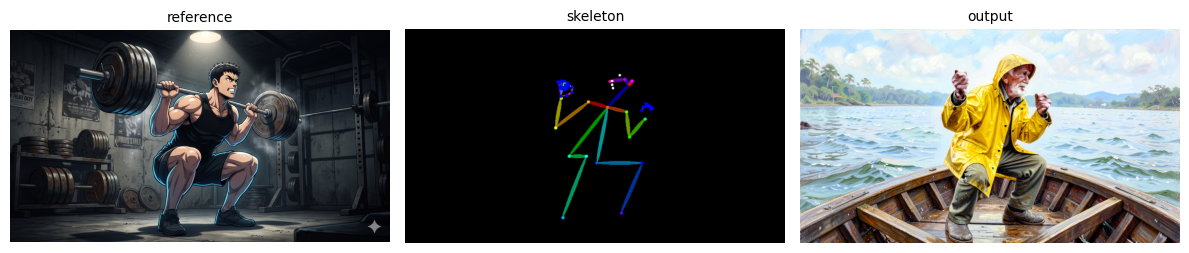

In [13]:
# 8) 포즈별로 이미지 생성 (결과는 메모리에 보관, 저장은 다음 셀에서)
subjects = [
    "a female astronaut in a white spacesuit on the surface of the moon, photorealistic",   # pose_01
    "a cute small robot made of shiny metal, 3D cartoon render, plain studio background",              # pose_02
    "an old fisherman in a yellow raincoat on a wooden boat, oil painting",               # pose_03
]

outputs = []
for sk, subj in zip(skeletons, subjects):
    outputs.append(generate_with_pose(sk, subj))

for p, s, o in zip(pose_photos, skeletons, outputs):
    show_row([Image.open(p), Image.open(s), o], ["reference", "skeleton", "output"])

## [단계 9] 결과 저장

생성한 이미지를 과제 폴더 구조에 맞는 이름으로 저장합니다.

| 파일 | 내용 |
|---|---|
| `samples/pose_0N.png` | 참조 사진 (단계 6에서 저장됨) |
| `samples/pose_0N_skeleton.png` | OpenPose 스켈레톤 (단계 7에서 저장됨) |
| `samples/output_0N.png` | **같은 자세로 만든 결과** |
| `samples/compare_0N.png` | 참조·스켈레톤·결과를 나란히 붙인 비교 그림 (README 에 넣기 좋음) |

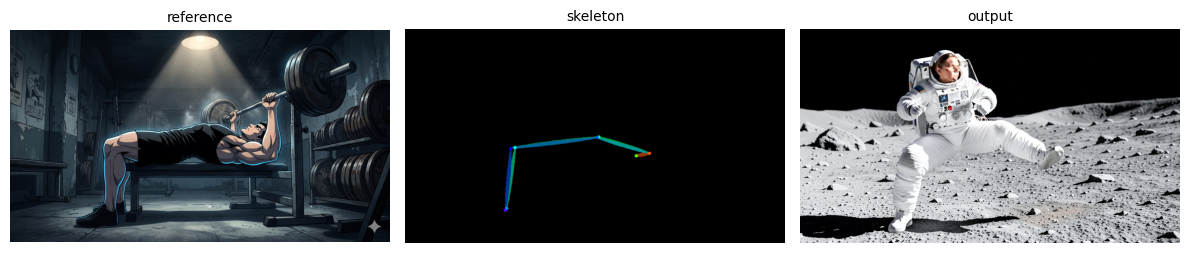

저장: /content/pose-image-tool/samples/output_01.png


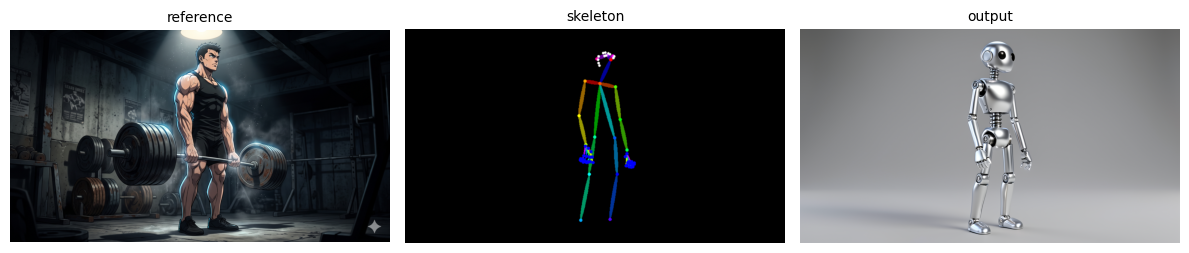

저장: /content/pose-image-tool/samples/output_02.png


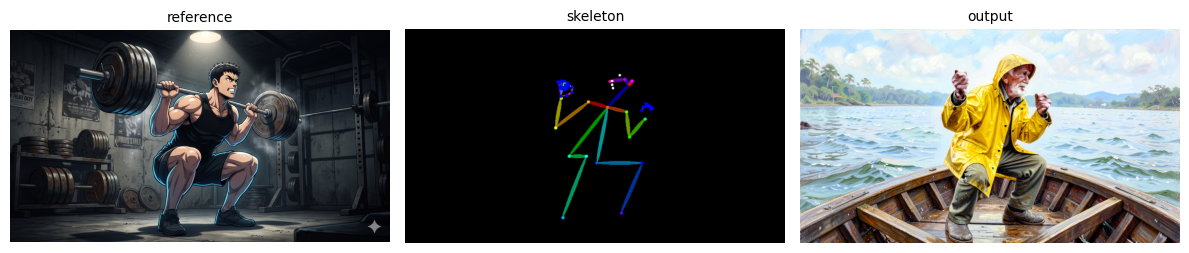

저장: /content/pose-image-tool/samples/output_03.png
total 27M
-rw-r--r-- 1 root root 280K Nov 11 07:57 compare_01.png
-rw-r--r-- 1 root root 214K Nov 11 07:57 compare_02.png
-rw-r--r-- 1 root root 328K Nov 11 07:57 compare_03.png
-rw-r--r-- 1 root root 813K Nov 11 07:46 exp_a_01.png
-rw-r--r-- 1 root root 505K Nov 11 07:46 exp_a_02.png
-rw-r--r-- 1 root root 1.2M Nov 11 07:46 exp_a_03.png
-rw-r--r-- 1 root root 547K Nov 11 07:46 exp_a_compare.png
-rw-r--r-- 1 root root 770K Nov 11 07:46 exp_a_no_pose.png
-rw-r--r-- 1 root root 1.1M Nov 11 07:49 exp_b_01.png
-rw-r--r-- 1 root root 1.1M Nov 11 07:49 exp_b_02.png
-rw-r--r-- 1 root root 1.1M Nov 11 07:49 exp_b_03.png
-rw-r--r-- 1 root root 551K Nov 11 07:49 exp_b_compare.png
-rw-r--r-- 1 root root 813K Nov 11 07:57 output_01.png
-rw-r--r-- 1 root root 508K Nov 11 07:57 output_02.png
-rw-r--r-- 1 root root 1.1M Nov 11 07:57 output_03.png
-rw-r--r-- 1 root root 5.4M Nov 11 07:28 pose_01.png
-rw-r--r-- 1 root root 6.1K Nov 11 07:28 pose_01_ske

In [14]:
# 9) 결과 이미지 + 비교 그림 저장
for i, (p, s, o) in enumerate(zip(pose_photos, skeletons, outputs), start=1):
    out_path = f"{SAMPLES}/output_{i:02d}.png"
    o.save(out_path)
    show_row([Image.open(p), Image.open(s), o], ["reference", "skeleton", "output"],
             save_path=f"{SAMPLES}/compare_{i:02d}.png")
    print("저장:", out_path)

!ls -lh {SAMPLES}

## [단계 10] 실험 A — 같은 포즈, 다른 프롬프트

**포즈(pose_01)와 시드는 고정**하고 프롬프트만 바꿉니다. 맨 끝에는 비교용으로 **포즈 조건 없이** 같은 프롬프트로 만든 이미지도 넣었습니다.

관찰할 점
- 인물·옷·배경·화풍이 바뀌어도 **팔·다리 각도는 그대로** 유지되나요?
- 사람이 아닌 대상(로봇)이나 그림 스타일(유화)에서도 자세를 따라오나요?
- 포즈 조건이 없을 때(마지막 칸)와 비교하면 자세가 얼마나 다른가요? → 포즈 조건의 효과를 직접 확인

  생성 완료 (28.1초, 1024x576, pose=ON) : a female astronaut in a white spacesuit on the surface of th
  생성 완료 (30.1초, 1024x576, pose=ON) : a cute small robot made of shiny metal, 3D cartoon render, p
  생성 완료 (28.1초, 1024x576, pose=ON) : an old fisherman in a yellow raincoat on a wooden boat, oil 
  생성 완료 (14.4초, 1024x576, pose=OFF) : a female astronaut in a white spacesuit on the surface of th


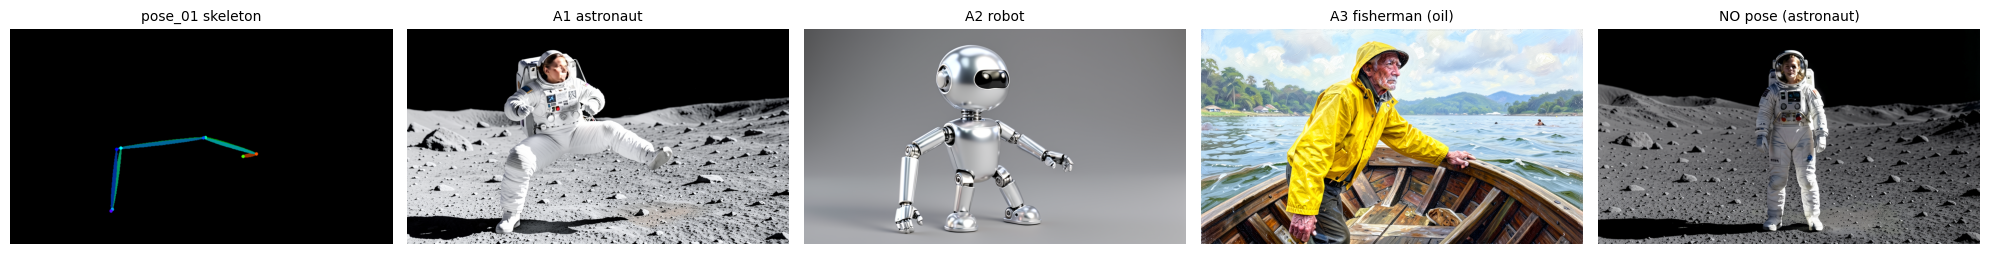

In [10]:
# 10) 실험 A: pose_01 고정 + 프롬프트 변경
exp_a_subjects = [
    "a female astronaut in a white spacesuit on the surface of the moon, photorealistic",
    "a cute small robot made of shiny metal, 3D cartoon render, plain studio background",
    "an old fisherman in a yellow raincoat on a wooden boat, oil painting",
]

exp_a = [generate_with_pose(skeletons[0], s) for s in exp_a_subjects]
baseline = generate_with_pose(None, exp_a_subjects[0], size=Image.open(skeletons[0]).size)   # 포즈 조건 OFF

for i, im in enumerate(exp_a, start=1):
    im.save(f"{SAMPLES}/exp_a_{i:02d}.png")
baseline.save(f"{SAMPLES}/exp_a_no_pose.png")

show_row([Image.open(skeletons[0])] + exp_a + [baseline],
         ["pose_01 skeleton", "A1 astronaut", "A2 robot", "A3 fisherman (oil)", "NO pose (astronaut)"],
         save_path=f"{SAMPLES}/exp_a_compare.png")

## [단계 11] 실험 B — 다른 포즈, 같은 프롬프트

이번엔 **프롬프트와 시드를 고정**하고 포즈(pose_01 ~ 03)만 바꿉니다.

관찰할 점
- 같은 인물 설명인데도 **자세가 포즈마다 확실히 달라지나요?**
- 앉은 자세처럼 팔다리가 겹치거나, 점프처럼 역동적인 자세에서도 잘 따라오나요?
- 프롬프트에 의자·배경을 적지 않았는데 앉은 자세라면 모델이 의자를 알아서 그리나요?
- 손가락·발 방향 같은 **세부**는 어느 정도까지 맞나요?

  생성 완료 (28.1초, 1024x576, pose=ON) : a young man in a red hoodie and blue jeans on a city street 
  생성 완료 (28.1초, 1024x576, pose=ON) : a young man in a red hoodie and blue jeans on a city street 
  생성 완료 (26.4초, 1024x576, pose=ON) : a young man in a red hoodie and blue jeans on a city street 


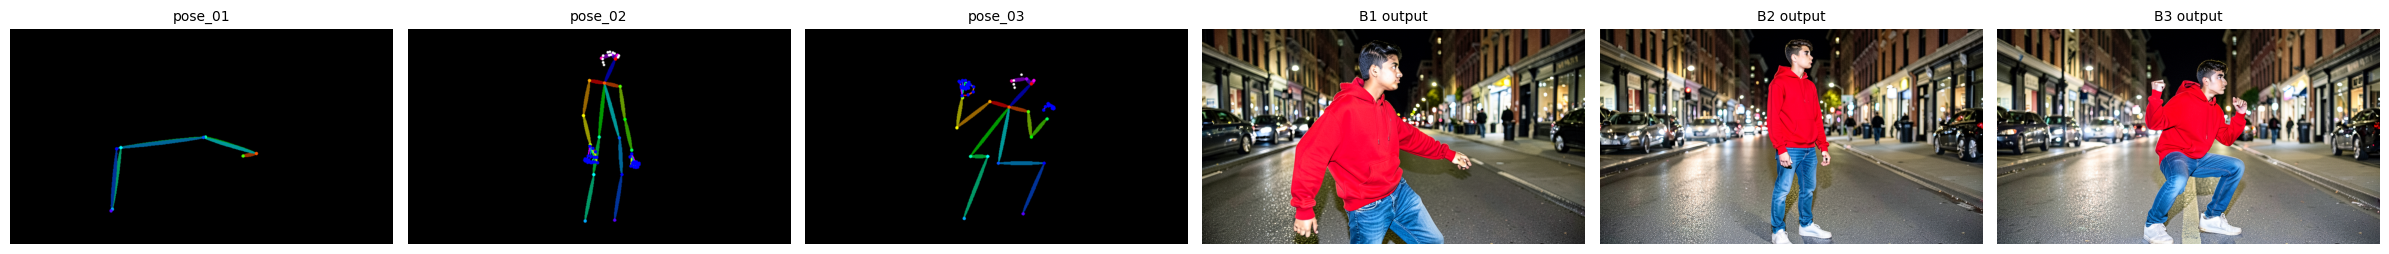

In [11]:
# 11) 실험 B: 프롬프트 고정 + 포즈 변경
exp_b_subject = "a young man in a red hoodie and blue jeans on a city street at night, photorealistic"

exp_b = [generate_with_pose(sk, exp_b_subject) for sk in skeletons]
for i, im in enumerate(exp_b, start=1):
    im.save(f"{SAMPLES}/exp_b_{i:02d}.png")

show_row([Image.open(s) for s in skeletons] + exp_b,
         [f"pose_{i:02d}" for i in range(1, len(skeletons)+1)] + [f"B{i} output" for i in range(1, len(exp_b)+1)],
         save_path=f"{SAMPLES}/exp_b_compare.png")

## [단계 12] 결과 내려받기

`samples` 폴더를 zip 으로 묶어 PC로 내려받습니다. 압축을 풀어 GitHub 저장소의 `samples/` 폴더에 그대로 올리면 됩니다.

> Colab 런타임이 끊기면 생성한 이미지가 모두 사라지므로, 실험이 끝나면 바로 내려받으세요.

In [15]:
# 12) samples 폴더를 zip 으로 묶어 다운로드
shutil.make_archive("/content/samples", "zip", SAMPLES)
files.download("/content/samples.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## [단계 13] 실험 관찰 기록 — 무엇을 바꿔 보았고, 어떻게 달라졌는가

> ✏️ **직접 실행한 결과를 보고 아래 `(작성)` 부분을 채우세요.** (이 셀을 더블클릭하면 편집할 수 있습니다)

### 고정한 조건
- 모델: FLUX.2-klein-4B (GGUF Q4) / 스텝 4 / CFG 4.0 / 시드 42
- 포즈 조건: OpenPose 스켈레톤(몸·손·얼굴) → ReferenceLatent

### 실험 A — 같은 포즈(pose_01), 다른 프롬프트

| # | 프롬프트 | 자세 일치 | 관찰 |
|---|---|---|---|
| A1 | astronaut on the moon | 하 | 누워있는 자세가 아니라 서서 다리만 벌림 |
| A2 | cute robot, 3D cartoon | 중 | 서있었으나 팔을 모으지 않고 벌림 |
| A3 | old fisherman, oil painting | 상 | 스쿼트 앉는 자세로 제대로 구현됨 |
| 비교 | astronaut, **포즈 조건 없음** |  | 정면을 쳐다보고 차렸자세로 있음 |

### 실험 B — 같은 프롬프트(red hoodie man), 다른 포즈

| # | 포즈 | 자세 일치 | 관찰 |
|---|---|---|---|
| B1 | pose_01 (벤치프레스 자세) | 불일치 | 서서 팔을 벌리는 자세를 취함|
| B2 | pose_02 (데드리프트 서있는 자세) | 일치 | 바벨을 없었으나 서있는 자세는 일치함 |
| B3 | pose_03 (스쿼트 앉은 자세) | 일치 | 바벨은 없었으나 스쿼트할 때 앉는 자세는 일치함 |

### 정리
- **결과가 크게 달라진 쪽**: (작성: 프롬프트를 바꿨을 때는 pose_1이, 포즈를 바꿨을 때는 pose_1이 달라졌다)
- **잘 따라온 것**: (전체적인 자세는 좋았음. 자세 자체가 세부적인 동작이 아니라 큰 동장을 잘 따라옴)
- **잘 안 따라온 것**: (누워있는 자세는 스켈레톤 선이 몸통인지 팔인지 다리인지 구분하지 못하는것 같음)
- **포즈와 프롬프트가 부딪힐 때**: (로봇처럼 사람 체형이 아닐때 사람을 따라갔으나 각도가 살짝 다름)
- **한계와 개선 아이디어**: (스켈레톤 선이 단순한것은 제대로 구현하지 못했다)

## 부록 — 자주 나는 문제

| 증상 | 해결 |
|---|---|
| `ComfyUI 실행 에러 ... ReferenceLatent` | ComfyUI 가 오래된 버전입니다. `/content/ComfyUI` 에서 `!git pull` 후 단계 4를 다시 실행 |
| 결과에 색깔 선(스켈레톤)이 그대로 보임 | 단계 5의 `CFG` 를 2.0 → 1.0 으로 낮추거나 시드를 바꿔 보기 |
| 자세를 거의 안 따라옴 | 스켈레톤(단계 7)이 제대로 그려졌는지 먼저 확인. 전신이 크게 나온 사진으로 바꾸기 |
| 스켈레톤이 비어 있음 | 사람이 너무 작거나 잘린 사진. 사람이 화면을 크게 채운 사진 사용 |
| `서버 연결 실패` / `Connection refused` | 단계 4 (서버 실행) 셀을 다시 실행 |
| 런타임이 끊김 | 단계 1부터 다시 실행 (모델은 이미 받았다면 건너뜀) |